Membros :
-Gabriel Faria Monteiro

-Livia Toledo Gandini

-Samuel Marques da Silva

Tema : Fatores que influenciam a performance dos estudantes

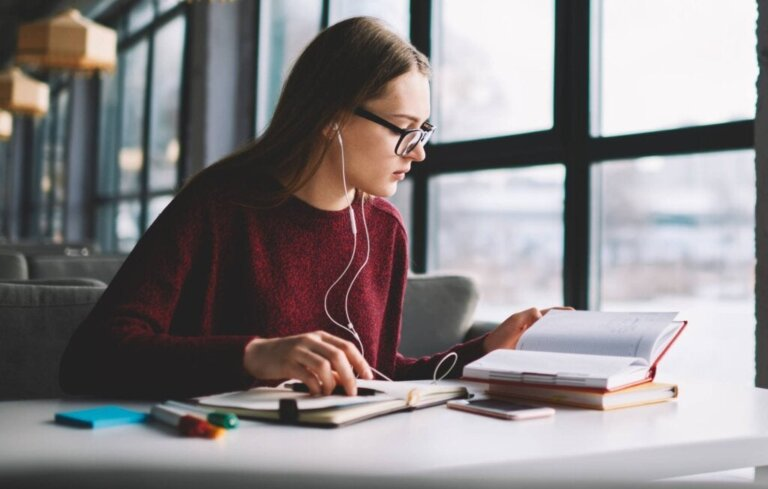


In [2]:
#Importando as bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
#dataset = pd.read_csv("datasets/games.csv", sep=";") Caminho github
dataset = pd.read_csv("StudentPerformanceFactors.csv",sep = ",") #Uso geral com google colab

print(f"Visualização dataset : ")
display(dataset)
print(f"Colunas do dataset: \n{dataset.columns}")

Visualização dataset : 


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


Colunas do dataset: 
Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')


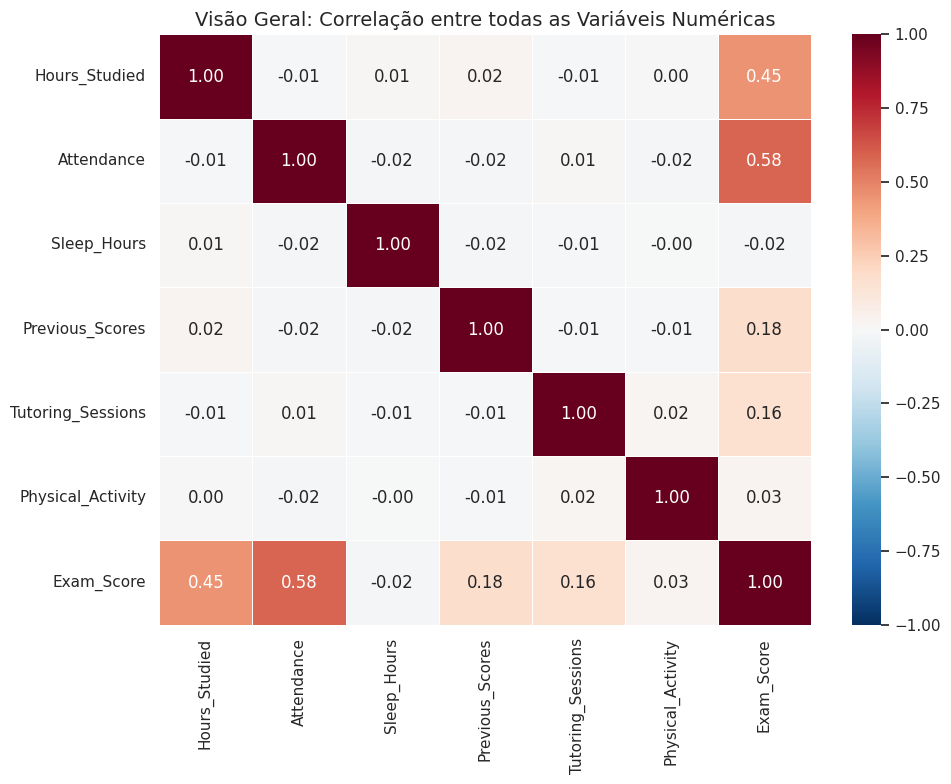

In [13]:
colunas_numericas = dataset.select_dtypes(include=['number', 'float64', 'int64'])


matriz_correlacao = colunas_numericas.corr()


plt.figure(figsize=(10, 8))


sns.heatmap(matriz_correlacao,
            annot=True,          # Mostra os números dentro dos quadrados
            cmap='RdBu_r',       # Esquema de cores (Azul para positivo, Vermelho para negativo)
            vmin=-1, vmax=1,     # Limites da correlação (-1 a 1)
            fmt='.2f',           # Formata para 2 casas decimais
            linewidths=0.5)      # Linhas separando os blocos

plt.title('Visão Geral: Correlação entre todas as Variáveis Numéricas', fontsize=14)
plt.tight_layout()
plt.show()

Como o tempo diário dedicado aos estudos (Hours Studied) impulsiona diretamente a nota final (Exam Score) do aluno ?

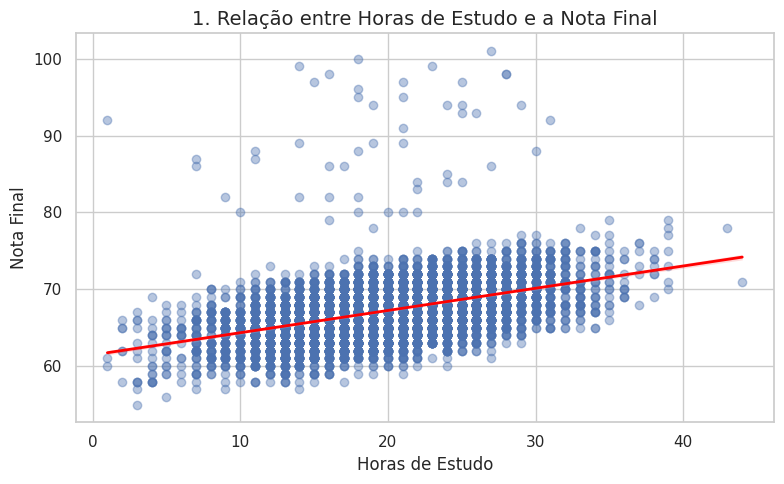

In [6]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8,5))

sns.regplot(
    data = dataset,
    x='Hours_Studied', y='Exam_Score',
    scatter_kws={'alpha':0.4, 'color':'#4C72B0'},
    line_kws={'color':'red', 'linewidth':2}
    )

plt.title('1. Relação entre Horas de Estudo e a Nota Final', fontsize=14)
plt.xlabel('Horas de Estudo', fontsize=12)
plt.ylabel('Nota Final', fontsize=12)

plt.tight_layout()
plt.show()


O gráfico de regressão evidencia uma correlação positiva clara entre o tempo dedicado aos estudos e o desempenho acadêmico. A linha de tendência vermelha demonstra que, de forma geral, o aumento nas horas de estudo acompanha uma elevação proporcional na nota final dos alunos. Embora exista uma dispersão natural dos pontos — indicando que fatores externos também influenciam o resultado —, a inclinação da reta confirma que a consistência no tempo de estudo atua como o principal motor estatístico para obter notas mais altas.

Qual é o perfil de distribuição das notas da turma? As avaliações concentram-se na média criando uma curva de sino padrão, ou há polarização nos extremos ?

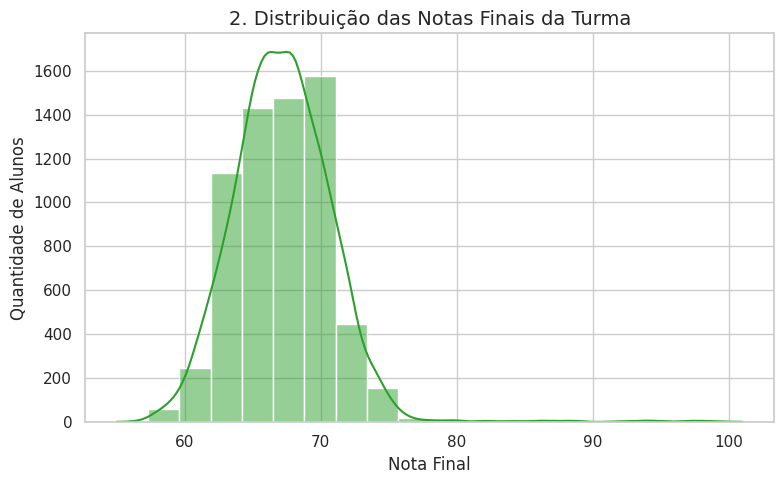

In [10]:
plt.figure(figsize=(8,5))
sns.histplot(data=dataset, x='Exam_Score', kde=True, color='#2CA02C', bins=20)
plt.title('2. Distribuição das Notas Finais da Turma', fontsize=14)
plt.xlabel('Nota Final', fontsize=12)
plt.ylabel('Quantidade de Alunos', fontsize=12)
plt.tight_layout()
plt.show()

O histograma revela o perfil de desempenho geral da turma. A curva de densidade traçada sobre as barras indica se a maioria dos alunos se concentra próximo à média, formando uma curva de sino tradicional, ou se há uma assimetria no rendimento que aponte para uma prova excepcionalmente fácil ou difícil.

Entre todas as métricas contínuas (Horas de Sono, Tempo de Estudo, Frequência e Notas Anteriores), qual exerce a maior correlação matemática sobre o sucesso na prova final ?

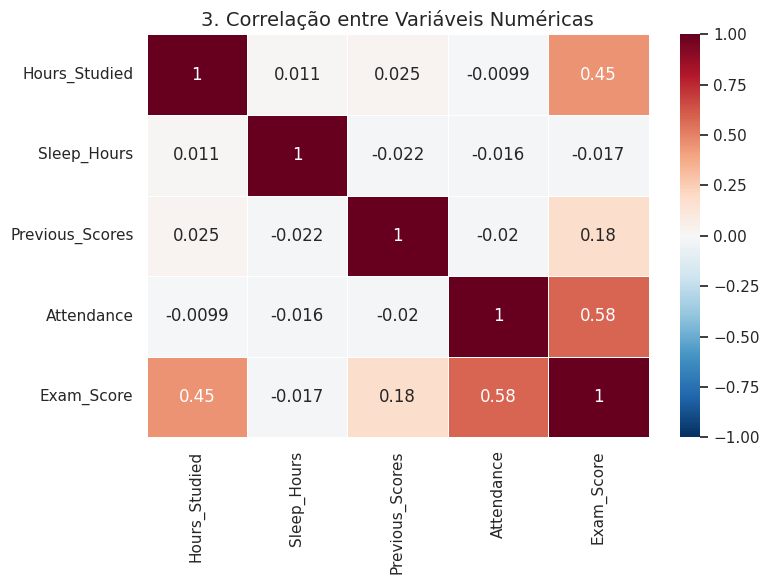

In [11]:
plt.figure(figsize=(8,6))
col_numericas = ['Hours_Studied', 'Sleep_Hours', 'Previous_Scores', 'Attendance', 'Exam_Score']
matriz_corr = dataset[col_numericas].corr()

sns.heatmap(matriz_corr, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, linewidths=.5)
plt.title('3. Correlação entre Variáveis Numéricas', fontsize=14)
plt.tight_layout()
plt.show()



O mapa de calor quantifica a força da relação matemática direta entre as variáveis numéricas do estudo. Os blocos com tons mais quentes e valores mais próximos de 1.0 evidenciam quais fatores exatos — como o histórico do aluno ou a sua assiduidade — exercem o maior peso estatístico na composição da nota final.